In [1]:
import pandas as pd
import numpy as np
import sys
sys.path.append('../')
from nova_clone.qc import pre_qc_complete_analysis
from nova_clone import clone_calling_algorithm
from nova_clone.qc import qc_complete_analysis

## Download and prepare the data 

In [ ]:
!wget --content-disposition "https://data.mendeley.com/public-files/datasets/t98pjcd7t6/files/4fa64df9-1e3c-4743-a1b9-1da8efd03404/file_downloaded"
!unzip M2.zip

In [3]:
# Load input data 
df = pd.read_csv('M2/output-files/pdac_mouse2_precluster_filtered.txt', sep='\t')

# keep only relevant columns
df = df[['cellID','intID','UMIs_per_intID_per_Cell']]

# Rename columns to standard names expected by the algorithm
df.columns = ['cellBC','intBC','UMI_count']
df.drop_duplicates(subset=['cellBC', 'intBC'], inplace=True)

## Step 1: Run Pre-QC Analysis

The `pre_qc_complete_analysis` function allow you to check the data, UMI distributions and number of distinct barcodes per cell

We recommend:
- Start with the default parameters.
- Adjust based on plots and.

Explanation of outputs:

- **Figure 1: UMI count quantiles table**
  Helps guide your choice of `min_intbc_umi_count`. In this dataset, values are low, so we use 2 (removes only ~5%).

- **Figure 2: Histogram of UMI counts per intBC**
  Visualize distribution of UMI counts to check filtering impact.

- **Figure 3: Distinct intBCs per cell**
  Shows how many intBCs are retained per cell after filtering. In this dataset, most cells have 1-2 intBCs. 
  *cells with 0 unique barcodes are cells that discarded 

- **Figure 4: Most frequent intBCs**
  Helps identify large clones based on highly frequent barcodes. In this dataset, there are two very frequent barcodes, sugget for one or two big clones.  

- **Figure 5: Distribution of Edit Distance**
  Visualize distribution of edit distances between intBCs. Helps guid your choice of `edit_distance_cutoff`. In this dataset, the default value of 4 will work well.

/Users/sprillo/Desktop/Git/nova-clone/notebooks/../nova_clone/qc/_pre_qc.py:189: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  intbc_table.groupby("cellBC").apply(


,5%,10%,15%,20%,25%,30%,35%,40%,45%,50%,55%,60%,65%,70%,75%,80%,85%,90%,95%
Max UMI_count,2.0,3.0,3.0,4.0,4.0,5.0,5.0,6.0,7.0,7.0,8.0,9.0,9.0,10.0,11.0,13.0,14.0,17.0,22.0


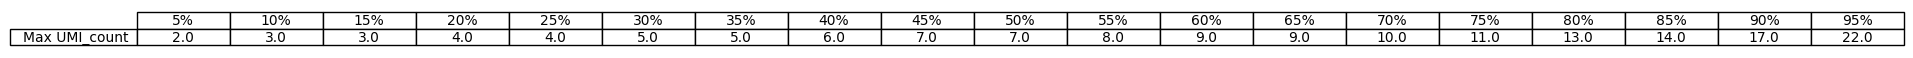

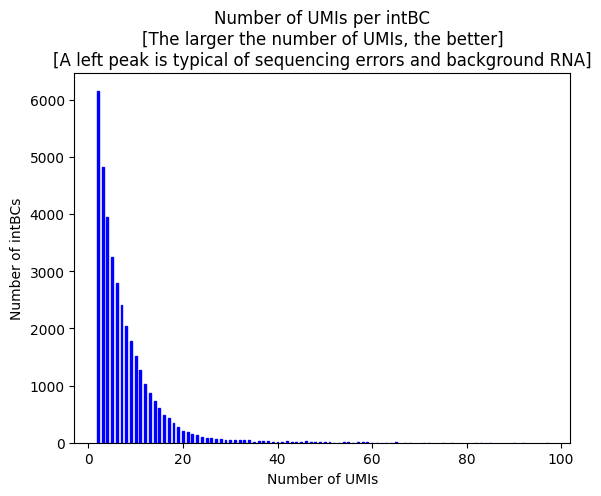

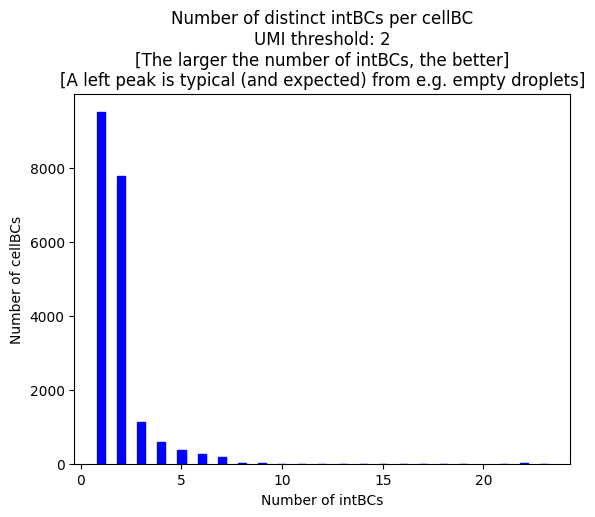

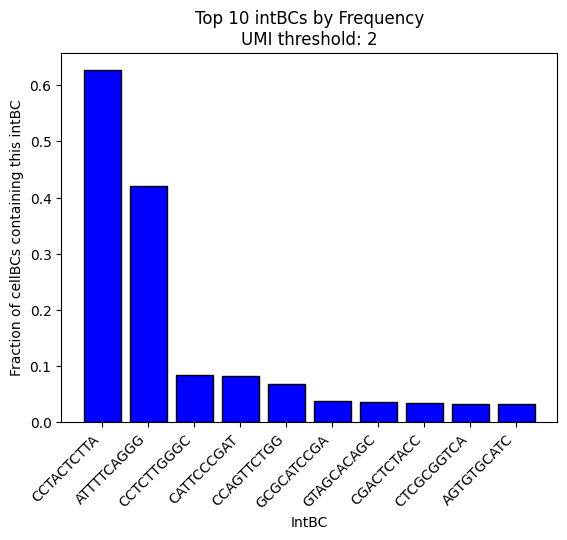

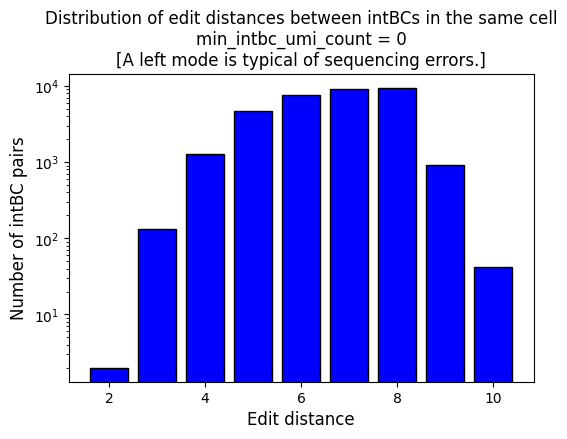

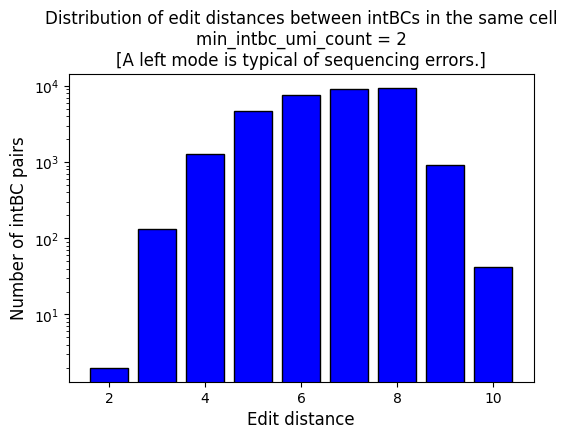

In [4]:
pre_qc_complete_analysis(
    intbc_table_per_sample={"sample0": df},
    min_intbc_umi_count=2
)

## Step 2: Run Clone-Calling

After determining a reasonable `min_intbc_umi_count` using the QC analysis, you can now run the clone-calling algorithm.

### Notes:
- If you're unsure about the parameters, we recommend starting with the **default settings**.
- A full list of parameters is available in the `clone_calling_algorithm` function docstring.
- Below are some of the **most commonly used and useful arguments**:

| Argument | Description |
|----------|-------------|
| `min_intbc_cellbc_count` | IntBCs that appear in fewer than this number of cellBCs will be discarded. |
| `min_intbc_umi_count` | IntBCs with fewer than this number of UMIs will be discarded. |
| `min_cells_assigned` | Minimum number of cells required per clone. Lower values will allow smaller clones to be identified. |
| `recursive` | If `True`, the algorithm will recursively analyze each clone to resolve subclonal structure (hierarchy of integrations). |

In [5]:
results = clone_calling_algorithm(
  intbc_table_per_sample={"sample0": df},
  min_intbc_umi_count=2,
  min_intbc_cellbc_count=2,
  min_cells_assigned=5,
  recursive=False,
)

*********************************************************************************
***** Phase 1 of algorithm: Construct clonal signatures (a.k.a. "coresets") *****
*********************************************************************************
[2026-05-10 14:12:28,978] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Going to prune_low_umi_count_intbcs ...
[2026-05-10 14:12:28,981] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Pruned 0.0% = 0 / 36528 rows from the intBC tables. [Lower is better.]
[2026-05-10 14:12:28,981] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Done with prune_low_umi_count_intbcs! Total time: 0.0024662017822265625
[2026-05-10 14:12:28,981] - nova_clone.algorithm._prune_custom_intbcs - INFO - Going to prune_custom_intbcs ...
[2026-05-10 14:12:28,986] - nova_clone.algorithm._prune_custom_intbcs - INFO - Pruned 0.0% = 0 / 36528 rows from the intBC tables. [Lower is better.]
[2026-05-10 14:12:28,986] - nova_clone.algorithm._p

/Users/sprillo/Desktop/Git/nova-clone/notebooks/../nova_clone/algorithm/_prune_low_cellbc_count_intbcs.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cellbc_counts = all_intbc_tables_concatenated.groupby("intBC").apply(


[2026-05-10 14:12:29,525] - nova_clone.algorithm._build_intbc_graph - INFO - IntBC graph has 194 nodes and 1182 edges. Density level: 6.31%
[2026-05-10 14:12:29,525] - nova_clone.algorithm._build_intbc_graph - INFO - Done with build_intbc_graph! Total time: 0.5316967964172363
[2026-05-10 14:12:29,526] - nova_clone.algorithm._prune_likely_sequencing_errors - INFO - Going to prune_likely_sequencing_errors ...
[2026-05-10 14:12:29,527] - nova_clone.algorithm._prune_likely_sequencing_errors - INFO - Pruned 19 likely sequencing errors. Pruned IntBC graph has 175 nodes and 876 edges.  Density level: 5.75%
[2026-05-10 14:12:29,527] - nova_clone.algorithm._prune_likely_sequencing_errors - INFO - Done with prune_likely_sequencing_errors! Total time: 0.000865936279296875
[2026-05-10 14:12:29,527] - nova_clone.algorithm._prune_likely_homoplastic_intbcs - INFO - Going to prune_likely_homoplastic_intbcs ...
[2026-05-10 14:12:29,528] - nova_clone.algorithm._prune_likely_homoplastic_intbcs - INFO - P

100%|██████████| 123/123 [00:00<00:00, 30252.71it/s]

[2026-05-10 14:12:29,550] - nova_clone.algorithm._find_maximal_coresets - INFO - Found 27 coresets, with average size 4.41
[2026-05-10 14:12:29,550] - nova_clone.algorithm._find_maximal_coresets - INFO - Done with find_maximal_coresets! Total time: 0.02030491828918457
[2026-05-10 14:12:29,551] - nova_clone.algorithm._clone_calling_algorithm - INFO - Going to compute_coreset_co_assignment_matrix ...


[2026-05-10 14:12:30,023] - nova_clone.algorithm._compute_coreset_co_assignment_matrix - INFO - Going to compute_coreset_co_assignment_matrix ...


... (2 outputs left out)

[2026-05-10 14:12:30,538] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Going to prune_low_umi_count_intbcs ...
[2026-05-10 14:12:30,540] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Pruned 0.0% = 0 / 36528 rows from the intBC tables. [Lower is better.]
[2026-05-10 14:12:30,541] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Done with prune_low_umi_count_intbcs! Total time: 0.0019431114196777344
[2026-05-10 14:12:30,999] - nova_clone.algorithm._compute_cellbc_vs_coreset_overlap_matrix - INFO - Going to compute_cellbc_vs_coreset_overlap_matrix ...


100%|██████████| 19899/19899 [00:00<00:00, 325934.82it/s]

[2026-05-10 14:12:31,127] - nova_clone.algorithm._compute_cellbc_vs_coreset_overlap_matrix - INFO - Done with compute_cellbc_vs_coreset_overlap_matrix! Total time: 0.12769508361816406



100%|██████████| 19899/19899 [00:00<00:00, 1985924.65it/s]


## Step 3: Run Post-QC Analysis

After clone calling, it's useful to assess the output quality using the post-analysis provided by `pre_qc_complete_analysis`.

This includes both **summary statistics** and **summary plots** to evaluate clone assignments, doublets, and homoplasy.

### Summary metrics:
- **Unmapped cells rate**: Percentage of cells that could not be confidently mapped to a clone (higher is better).
- **Doublet and multiplet rate**: Percentage of cells assigned to multiple clones (lower is better).
- **Homoplasy analysis**: Identifies IntBCs shared across multiple clones and the number of cells they occur in for each clone.

### Figures:
- **Figure 1: Clone sizes and average number of intBCs per clone**  
  Visualizes the number of cells in each clone and their average number of intBCs.

- **Figure 2: Multiplet rate in clones**  
  Histogram showing rates of doublets/multiplets in the clones.

- **Figure 3: Percent of UMIs kept in successfully mapped cells**  
  Distribution of retained UMIs per cell. A peak near 100% is ideal.

- **Figure 4: IntBCs in the 10 largest clones**  
  For each clone:
  - Each bar represents an intBC.
  - **Blue** bars: core set intBCs  
  - **Red** bars: other associated intBCs  
  - **Green line**: number of cells assigned to the clone  
  - X-axis labels: intBC sequence, average UMI count (`u`), and edit distance from the nearest barcode (`d`)

******************************
****** Doublet Analysis ******
******************************
Unmapped cellBCs: 50.76% = 10100 / 19899 [the lower the better]
Uniquely (i.e. successfully) mapped cellBCs: 48.37% = 9625 / 19899 [the higher the better]
Doublet cellBCs: 0.86% = 172 / 19899 [should match expectations]
Multiplet cellBCs (degree 3): 0.01% = 2 / 19899 [should match expectations]
************************************************
****** Clone sizes and tracing capacities ******
************************************************


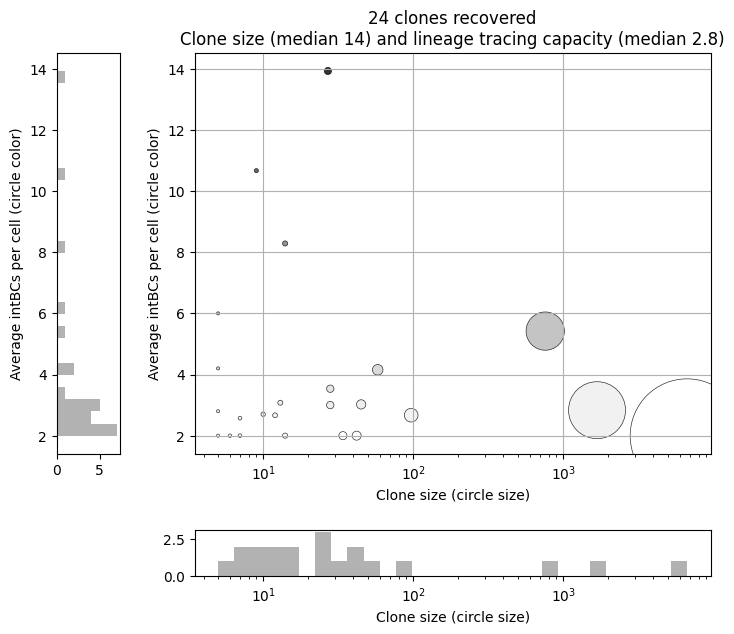

******************************
* Per-Clone Doublet Analysis *
******************************


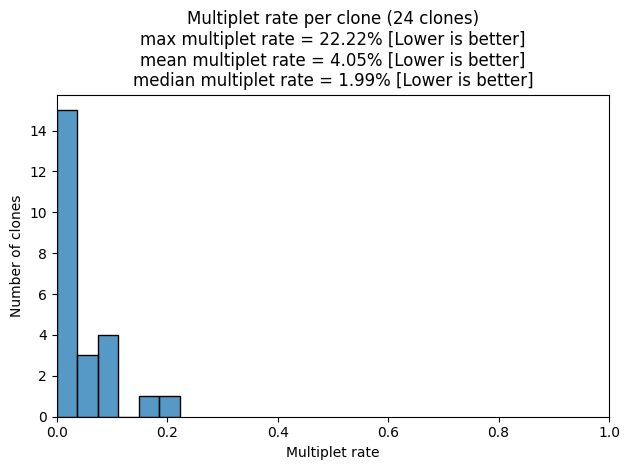

******************************
***** Homoplasy Analysis *****
******************************
No homoplastic intBCs found amongst the called clones.


100%|██████████| 24/24 [00:00<00:00, 582.31it/s]


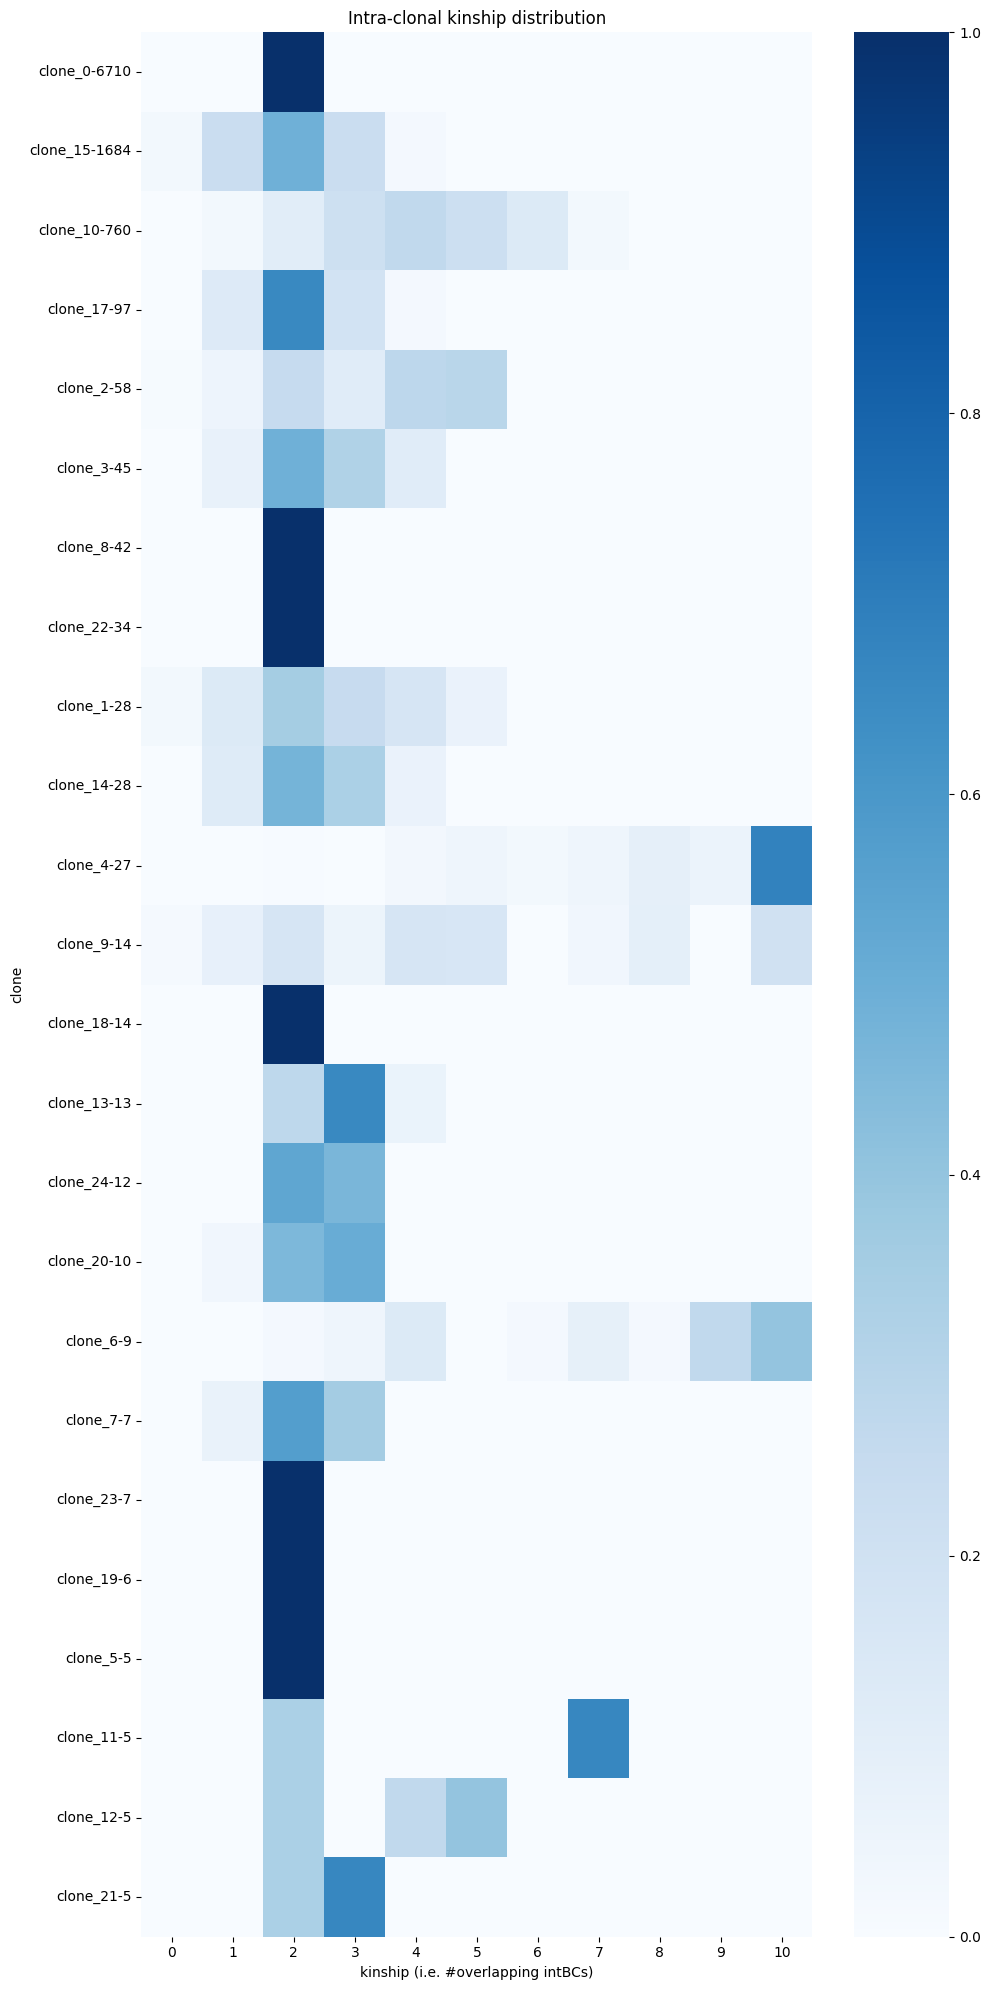

Clone clone_15 has a mean kinship of 1.99 which is less than 2.
This suggests low lineage tracing capacity or a clone with an incoherent set of cells.
You might want to exclude this clone from further analysis.
*****************************************
***** Inter-Clonal Kinship Analysis *****
*****************************************
***********************************
***** Data Retention Analysis *****
***********************************
Percent of UMIs kept in successfully mapped cellBCs: 97.86% [higher is better]



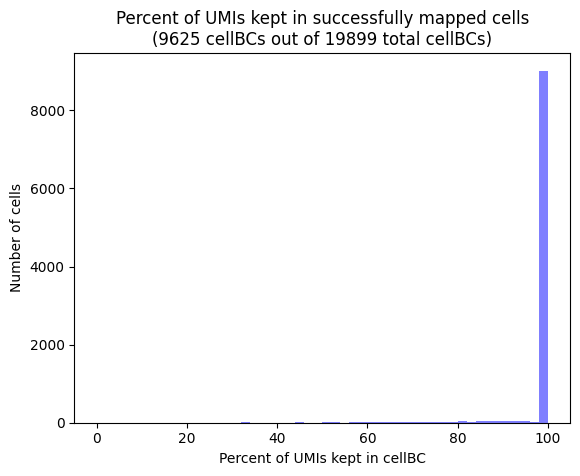

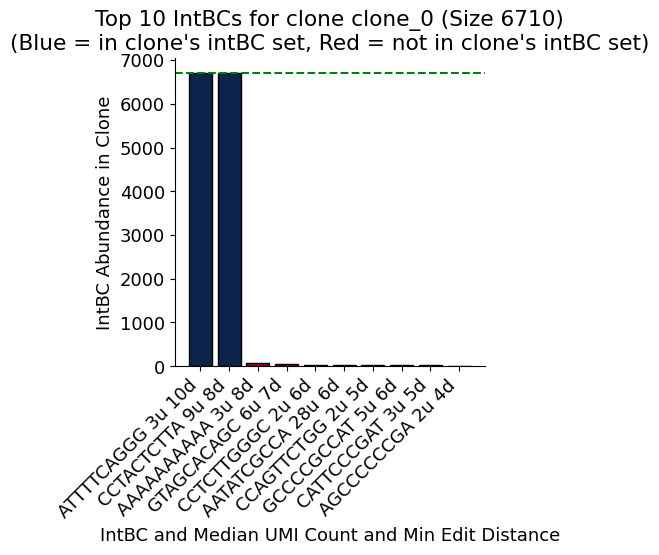

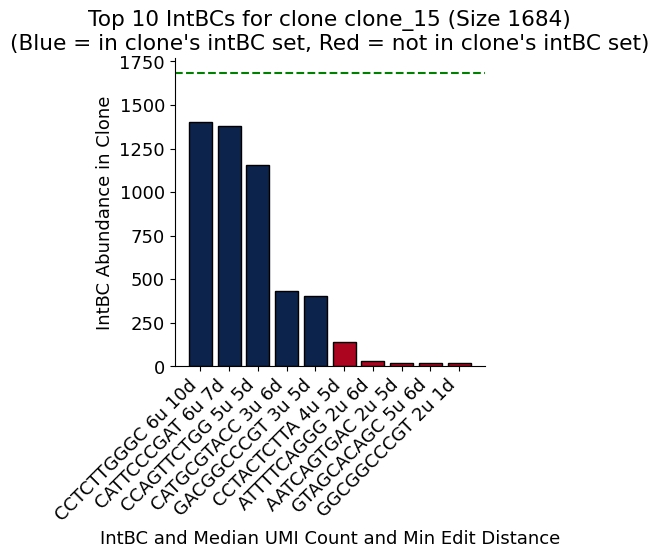

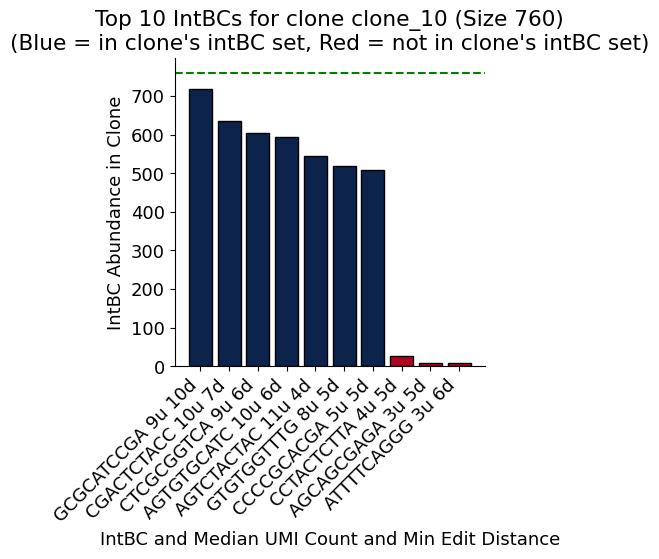

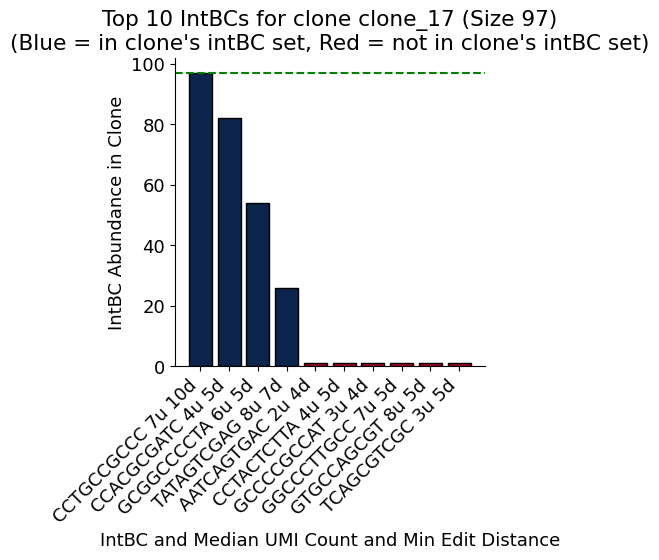

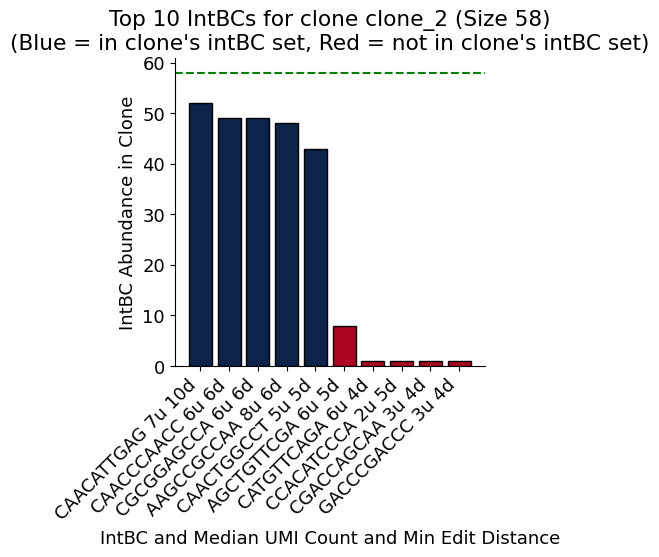

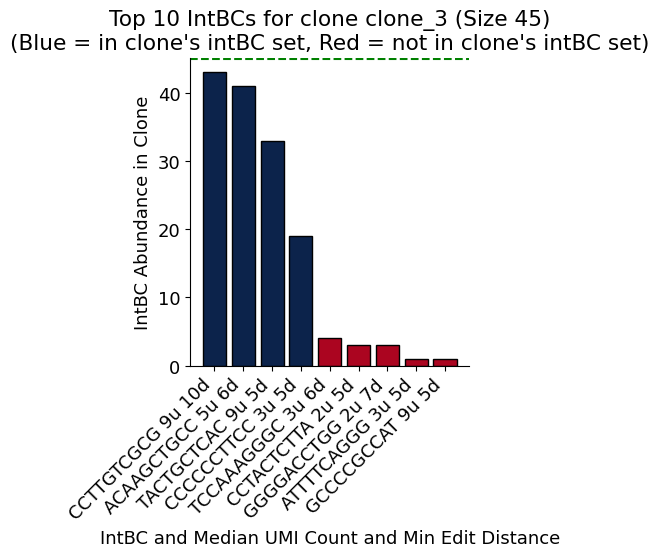

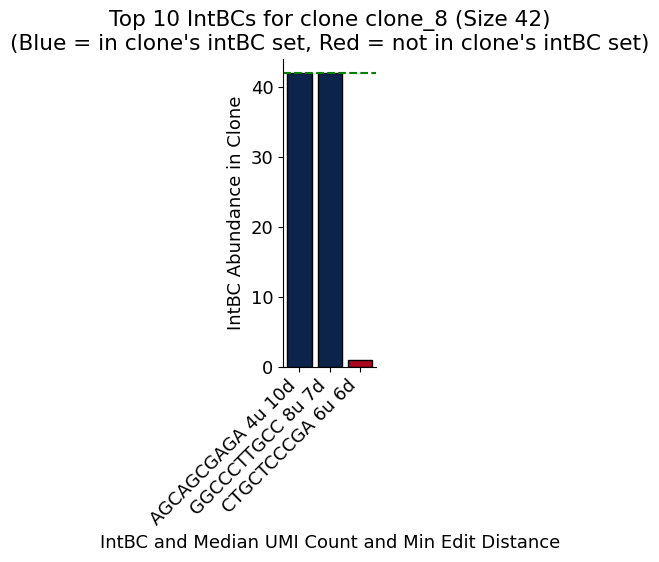

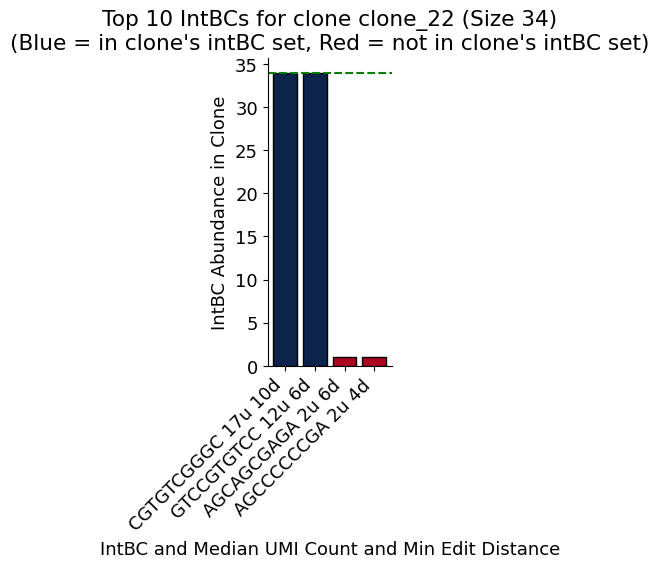

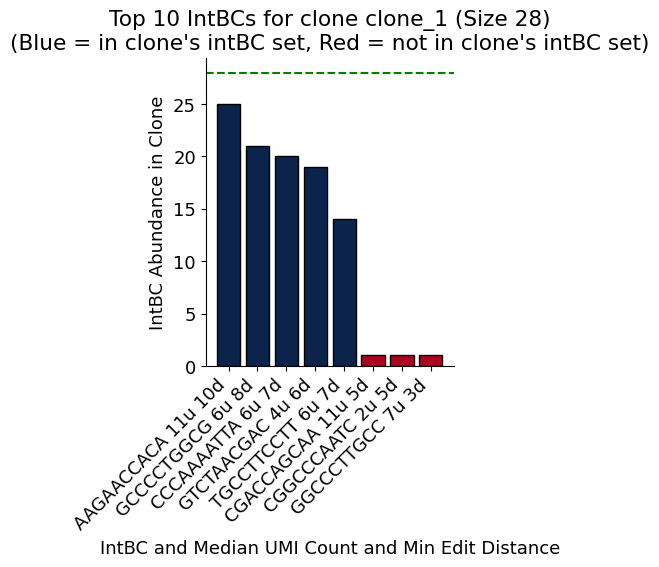

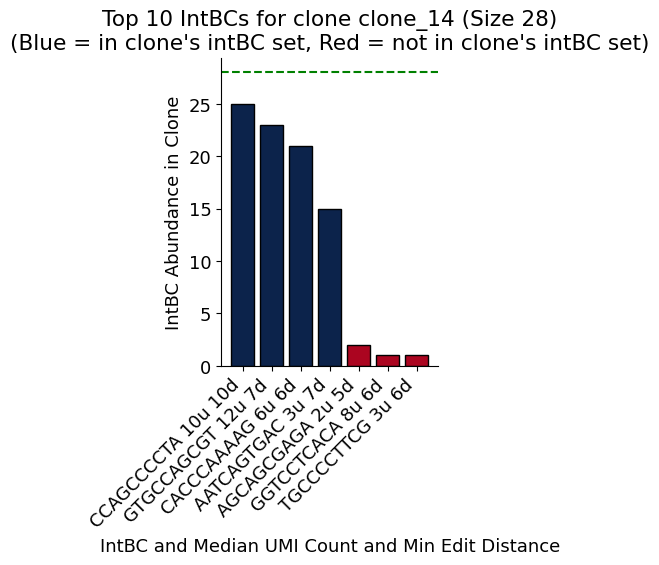

In [6]:
qc_complete_analysis(
    intbc_table_per_sample={"sample0": df},    
    clone_call=results.clone_call,
)

## Step 4: Inspect Results

The `clone_calling_algorithm` returns a structured `results` object containing the arrtibutes: `clone_call`, `recursive_clone_call_integration_hierarchy`, `recursive_clone_call` and `metadata`.

### Most relevant outputs:

- `results.clone_call.cell_to_clones_mapping`:  
  Dictionary mapping each `cellBC` to one or more clone IDs. Cells that are multiplets will have multiple assignments.

- `results.clone_call.clone_to_cells_mapping`:  
  Dictionary mapping each clone ID to a list of `cellBCs` that belong to that clone.

- `results.clone_call.clone_intbc_sets`:  
  Dictionary mapping each clone ID to its core set of IntBCs.

In [7]:
results.clone_call.cell_to_clones_mapping

{'sample0_Liver_AAACCCAAGTTCATCG': set(),
 'sample0_Liver_AAACCCAAGTTCGGTT': set(),
 'sample0_Liver_AAACCCAAGTTGCGCC': set(),
 'sample0_Liver_AAACCCACAGTTAGGG': set(),
 'sample0_Liver_AAACCCACATGCGGTC': set(),
 'sample0_Liver_AAACCCAGTTGAGTCT': set(),
 'sample0_Liver_AAACCCATCCCTTGTG': set(),
 'sample0_Liver_AAACCCATCGTCTACC': set(),
 'sample0_Liver_AAACGAAAGAAATTCG': set(),
 'sample0_Liver_AAACGAAAGAGGGTGG': {'clone_17'},
 'sample0_Liver_AAACGAACACCTCGTT': set(),
 'sample0_Liver_AAACGAAGTCTACGAT': set(),
 'sample0_Liver_AAACGAAGTGATACAA': set(),
 'sample0_Liver_AAACGCTAGAGTGAAG': set(),
 'sample0_Liver_AAACGCTCACAACATC': {'clone_0'},
 'sample0_Liver_AAACGCTCAGCTGAGA': set(),
 'sample0_Liver_AAACGCTTCCATGCAA': set(),
 'sample0_Liver_AAAGAACCAGCGCGTT': set(),
 'sample0_Liver_AAAGAACTCGCTGTTC': set(),
 'sample0_Liver_AAAGAACTCGGAATTC': set(),
 'sample0_Liver_AAAGAACTCTACTTCA': set(),
 'sample0_Liver_AAAGGATAGCTGTGCC': {'clone_0'},
 'sample0_Liver_AAAGGATAGGAACGCT': set(),
 'sample0_Liver

In [8]:
results.clone_call.clone_to_cells_mapping

{'clone_0': {'sample0_Met_TAGAGTCGTTGGGATG',
  'sample0_Met_AAACCCACAGTGTACT',
  'sample0_Met_GATCATGTCCGTTGGG',
  'sample0_Liver_CTCAAGATCGATAACC',
  'sample0_Met_TACGGGCGTTTCCATT',
  'sample0_Met_GGGCCATAGCATGAAT',
  'sample0_Liver_ATGACCAAGGTCTACT',
  'sample0_Liver_CTATCCGGTGAGACCA',
  'sample0_Liver_GTCCCATAGTCCTGTA',
  'sample0_Liver_TGCAGTATCACGATAC',
  'sample0_Met_GGGACCTAGGGACAGG',
  'sample0_Met_GAGTTGTCAAGCTCTA',
  'sample0_Liver_GGATGTTGTCGTTCAA',
  'sample0_Liver_CTGCATCGTATCGATC',
  'sample0_Met_TCCACCACAGAGGTAC',
  'sample0_Met_AGCCAGCAGTATTAGG',
  'sample0_Met_AGCTTCCAGTCAGCCC',
  'sample0_Met_AACAGGGCACCACATA',
  'sample0_Met_ATGCCTCAGAAGTGTT',
  'sample0_Met_AACTTCTTCGACCCAG',
  'sample0_Met_TTGCTGCAGGCTGGAT',
  'sample0_Liver_GATGATCTCTGCGGAC',
  'sample0_Liver_TTCCTTCTCAAACGAA',
  'sample0_Liver_CCAAGCGGTAGGTAGC',
  'sample0_Met_TTCCGTGTCTCGTGGG',
  'sample0_Met_AGAGAGCCATTGGGAG',
  'sample0_Met_TGATTTCCAGATACCT',
  'sample0_Liver_GAGACCCGTACAGGTG',
  'sample0_Met_

In [9]:
results.clone_call.clone_intbc_sets

{'clone_0': {'ATTTTCAGGG', 'CCTACTCTTA'},
 'clone_1': {'AAGAACCACA',
  'CCCAAAATTA',
  'GCCCCTGGCG',
  'GTCTAACGAC',
  'TGCCTTCCTT'},
 'clone_2': {'AAGCCGCCAA',
  'CAACATTGAG',
  'CAACCCAACC',
  'CAACTGGCCT',
  'CGCGGAGCCA'},
 'clone_3': {'ACAAGCTGCC', 'CCCCCCTTCC', 'CCTTGTCGCG', 'TACTGCTCAC'},
 'clone_4': {'ACACACAAGC',
  'ACCGCCACCC',
  'AGCAGTACTT',
  'CAAGCCCTCA',
  'CCACGGGTTC',
  'CCCACTCGGG',
  'CGCCTTCCCG',
  'CGCTAAGTCC',
  'CGCTCCCTAT',
  'CGGACCGCTG',
  'GACGCGAGCC',
  'GCCCAAGTAC',
  'GCCCGCCTGA',
  'GCCTGCTCAA',
  'TACCCACCCG',
  'TTGAGCGGAC',
  'TTTTCCCGAA'},
 'clone_5': {'ACCACCAAAA', 'GGCAACCGAC'},
 'clone_6': {'ACGGTACTGC',
  'AGAGAGGCTC',
  'CATGTGACAC',
  'CCAGCTTTGC',
  'CCCGGCACAA',
  'CGACCCCGAA',
  'CGATCTCGGC',
  'GACGCAACTT',
  'GCTATGTACT',
  'GGCTCACTTT',
  'GGGCAATGAG',
  'GGGGCCTGGC',
  'TCAATAATGA',
  'TGCCCGTCGC'},
 'clone_7': {'ACTCAAGATT', 'CAGGACGCGC', 'TTCTCAGCGT'},
 'clone_8': {'AGCAGCGAGA', 'GGCCCTTGCC'},
 'clone_9': {'AGCTATCCAC',
  'CAGCACTAGG',
 